<a href="https://colab.research.google.com/github/Alk207-lab/-Machine-learning-projects-Sem1/blob/main/Ex8_Credit_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 7: Credit Risk Assessment

## Aim
Build a credit scoring model to assess the creditworthiness of applicants using historical financial data and perform a comparative analysis of **Logistic Regression** and **Random Forest**.

## Objectives
- Load and understand the credit-risk dataset.
- Perform basic data preprocessing and exploratory analysis.
- Train Logistic Regression and Random Forest classification models.
- Evaluate both models using multiple classification metrics.
- Compare their performance and identify the more suitable model for this dataset.


## Dataset Description
The dataset contains applicant demographic and financial attributes. The target variable is `Credit_Risk`, with three categories: **Low**, **Medium**, and **High**.

`Applicant_ID` is only an identifier, so it is excluded from model training.

In [1]:
# Import required libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc
)

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

In [2]:
# Load dataset
# Keep the CSV in the same folder as this notebook.
DATA_PATH = 'credit_risk_assessment_500_samples.csv'
df = pd.read_csv(DATA_PATH)

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (500, 11)


,Applicant_ID,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Loan_Term_Months,Existing_Loans_Count,Debt_to_Income_Ratio,Late_Payments_Last_2Yrs,Credit_Risk
0,1,59,153267,28,818,196649,12,2,0.68,0,High
1,2,49,232745,0,436,175354,60,0,0.23,5,High
2,3,35,974945,19,797,662297,48,3,0.54,0,Medium
3,4,63,307164,29,776,831725,48,0,0.56,4,High
4,5,28,685626,6,893,498625,60,3,0.66,8,High


In [3]:
# Basic information
print('Column names:')
print(df.columns.tolist())
print('\nData types:')
print(df.dtypes)
print('\nMissing values:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Column names:
['Applicant_ID', 'Age', 'Annual_Income', 'Employment_Years', 'Credit_Score', 'Loan_Amount', 'Loan_Term_Months', 'Existing_Loans_Count', 'Debt_to_Income_Ratio', 'Late_Payments_Last_2Yrs', 'Credit_Risk']

Data types:
Applicant_ID                 int64
Age                          int64
Annual_Income                int64
Employment_Years             int64
Credit_Score                 int64
Loan_Amount                  int64
Loan_Term_Months             int64
Existing_Loans_Count         int64
Debt_to_Income_Ratio       float64
Late_Payments_Last_2Yrs      int64
Credit_Risk                 object
dtype: object

Missing values:
Applicant_ID               0
Age                        0
Annual_Income              0
Employment_Years           0
Credit_Score               0
Loan_Amount                0
Loan_Term_Months           0
Existing_Loans_Count       0
Debt_to_Income_Ratio       0
Late_Payments_Last_2Yrs    0
Credit_Risk                0
dtype: int64

Duplicate rows: 0


In [4]:
# Statistical summary
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Applicant_ID,500.0,NaN,NaN,NaN,250.5,144.481833,1.0,125.75,250.5,375.25,500.0
Age,500.0,NaN,NaN,NaN,43.116,12.733217,21.0,32.0,44.0,53.0,64.0
Annual_Income,500.0,NaN,NaN,NaN,827131.654,384829.861761,150404.0,506262.25,833427.5,1148353.0,1498464.0
Employment_Years,500.0,NaN,NaN,NaN,14.702,8.713498,0.0,7.0,15.5,22.0,29.0
Credit_Score,500.0,NaN,NaN,NaN,596.394,171.339795,300.0,452.0,602.0,732.25,898.0
Loan_Amount,500.0,NaN,NaN,NaN,521385.53,281799.514154,55901.0,266621.75,533640.0,765362.5,999621.0
Loan_Term_Months,500.0,NaN,NaN,NaN,37.032,17.117037,12.0,24.0,36.0,48.0,60.0
Existing_Loans_Count,500.0,NaN,NaN,NaN,2.058,1.419389,0.0,1.0,2.0,3.0,4.0
Debt_to_Income_Ratio,500.0,NaN,NaN,NaN,0.4097,0.175077,0.1,0.25,0.42,0.56,0.7
Late_Payments_Last_2Yrs,500.0,NaN,NaN,NaN,4.49,2.940611,0.0,2.0,5.0,7.0,9.0


## Exploratory Data Analysis
First, inspect the distribution of the target classes. This is important because an imbalanced target can make accuracy alone misleading.

Credit_Risk
High      315
Medium    164
Low        21
Name: count, dtype: int64


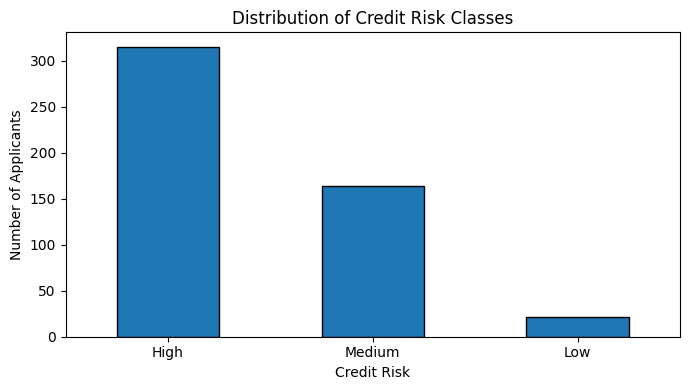

In [5]:
# Target class distribution
risk_counts = df['Credit_Risk'].value_counts()
print(risk_counts)

ax = risk_counts.plot(kind='bar', figsize=(7, 4), edgecolor='black')
ax.set_title('Distribution of Credit Risk Classes')
ax.set_xlabel('Credit Risk')
ax.set_ylabel('Number of Applicants')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

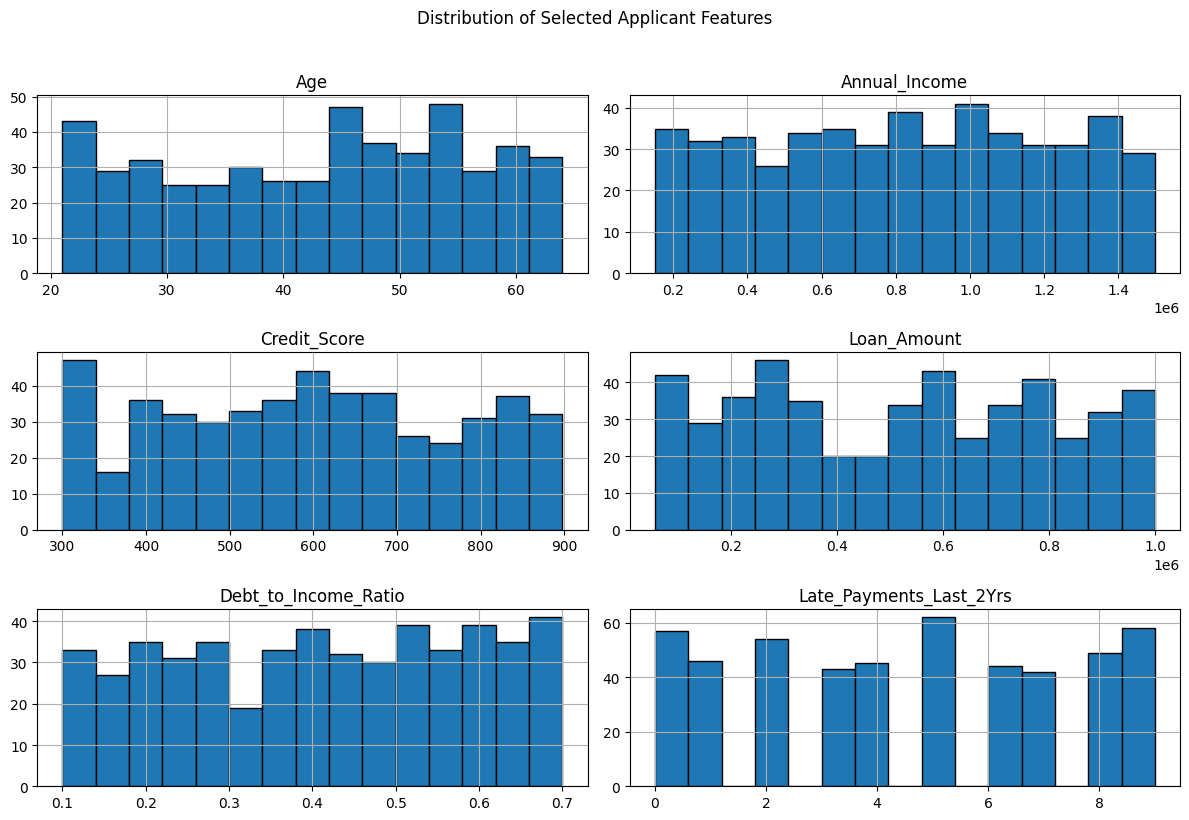

In [6]:
# Histograms of important numerical features
features_to_plot = ['Age', 'Annual_Income', 'Credit_Score',
                    'Loan_Amount', 'Debt_to_Income_Ratio',
                    'Late_Payments_Last_2Yrs']

df[features_to_plot].hist(figsize=(12, 8), bins=15, edgecolor='black')
plt.suptitle('Distribution of Selected Applicant Features', y=1.02)
plt.tight_layout()
plt.show()

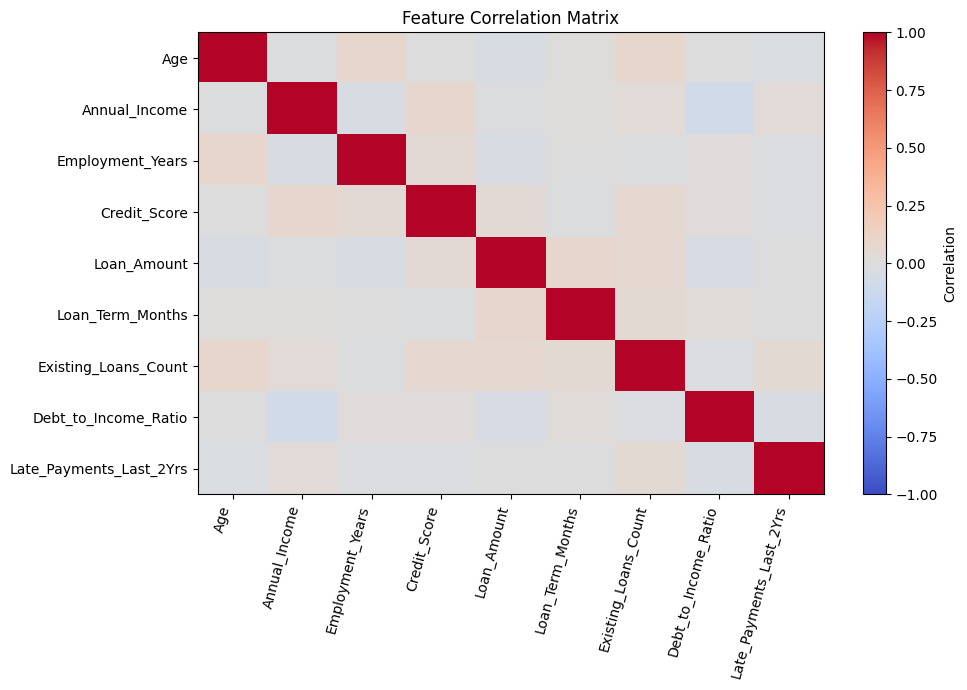

In [7]:
# Correlation matrix for numerical predictors
numeric_df = df.drop(columns=['Applicant_ID', 'Credit_Risk'])
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr, aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=75, ha='right')
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

## Data Preprocessing
- `Applicant_ID` is removed because it does not describe creditworthiness.
- The remaining columns are used as input features.
- `Credit_Risk` is the target.
- A **stratified 80:20 split** preserves the class proportions in training and testing data.
- Standardization is applied for Logistic Regression. Random Forest is trained on the original feature scale because tree-based models do not require scaling.

In [8]:
# Separate features and target
X = df.drop(columns=['Applicant_ID', 'Credit_Risk'])
y = df['Credit_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Training set:', X_train.shape)
print('Testing set :', X_test.shape)
print('\nTraining target distribution:')
print(y_train.value_counts())
print('\nTesting target distribution:')
print(y_test.value_counts())

Training set: (400, 9)
Testing set : (100, 9)

Training target distribution:
Credit_Risk
High      252
Medium    131
Low        17
Name: count, dtype: int64

Testing target distribution:
Credit_Risk
High      63
Medium    33
Low        4
Name: count, dtype: int64


In [9]:
# Standardize features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Model 1: Logistic Regression
Logistic Regression estimates class probabilities from a weighted combination of input features. For this multiclass problem, scikit-learn handles the multiclass classification automatically.

`class_weight='balanced'` is used because the dataset contains substantially fewer Low-risk records than High-risk records.

In [10]:
log_model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=RANDOM_STATE
)
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)
log_prob = log_model.predict_proba(X_test_scaled)

print('Logistic Regression trained successfully.')

Logistic Regression trained successfully.


## Model 2: Random Forest
Random Forest combines many decision trees and uses majority voting for classification. It can model nonlinear relationships and feature interactions. Balanced class weights are again used to reduce the effect of class imbalance.

In [11]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight='balanced',
    min_samples_leaf=2
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)

print('Random Forest trained successfully.')

Random Forest trained successfully.


## Evaluation Metrics
The models are compared using:
- **Accuracy:** overall proportion of correct predictions.
- **Macro Precision:** precision calculated per class and averaged equally.
- **Macro Recall:** recall calculated per class and averaged equally.
- **Macro F1-score:** harmonic mean of precision and recall, averaged equally across classes.
- **Balanced Accuracy:** average recall across classes, useful for imbalanced datasets.
- **ROC-AUC (OvR):** multiclass probability-ranking performance using One-vs-Rest.

In [12]:
# Reusable evaluation function
def evaluate_model(name, model, X_eval, y_true, y_pred, y_prob):
    classes = model.classes_
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision (Macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall (Macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 Score (Macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'ROC-AUC (OvR Macro)': roc_auc_score(y_true, y_prob, labels=classes,
                                             multi_class='ovr', average='macro')
    }

results = pd.DataFrame([
    evaluate_model('Logistic Regression', log_model, X_test_scaled, y_test, log_pred, log_prob),
    evaluate_model('Random Forest', rf_model, X_test, y_test, rf_pred, rf_prob)
]).set_index('Model')

display(results.round(4))

,Accuracy,Balanced Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro),ROC-AUC (OvR Macro)
Model,,,,,,
Logistic Regression,0.79,0.8456,0.6925,0.8456,0.7398,0.9358
Random Forest,0.99,0.9167,0.9902,0.9167,0.9474,1.0000


In [13]:
# Detailed classification reports
print('LOGISTIC REGRESSION - CLASSIFICATION REPORT')
print(classification_report(y_test, log_pred, zero_division=0))

print('RANDOM FOREST - CLASSIFICATION REPORT')
print(classification_report(y_test, rf_pred, zero_division=0))

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.91      0.81      0.86        63
         Low       0.50      1.00      0.67         4
      Medium       0.67      0.73      0.70        33

    accuracy                           0.79       100
   macro avg       0.69      0.85      0.74       100
weighted avg       0.81      0.79      0.80       100

RANDOM FOREST - CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        63
         Low       1.00      0.75      0.86         4
      Medium       0.97      1.00      0.99        33

    accuracy                           0.99       100
   macro avg       0.99      0.92      0.95       100
weighted avg       0.99      0.99      0.99       100



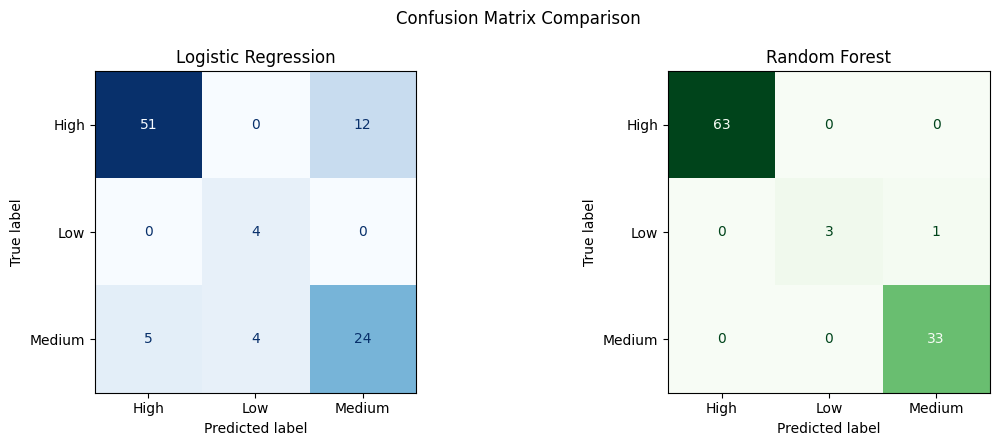

In [14]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, log_pred, ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, ax=axes[1], cmap='Greens', colorbar=False
)
axes[1].set_title('Random Forest')

plt.suptitle('Confusion Matrix Comparison')
plt.tight_layout()
plt.show()

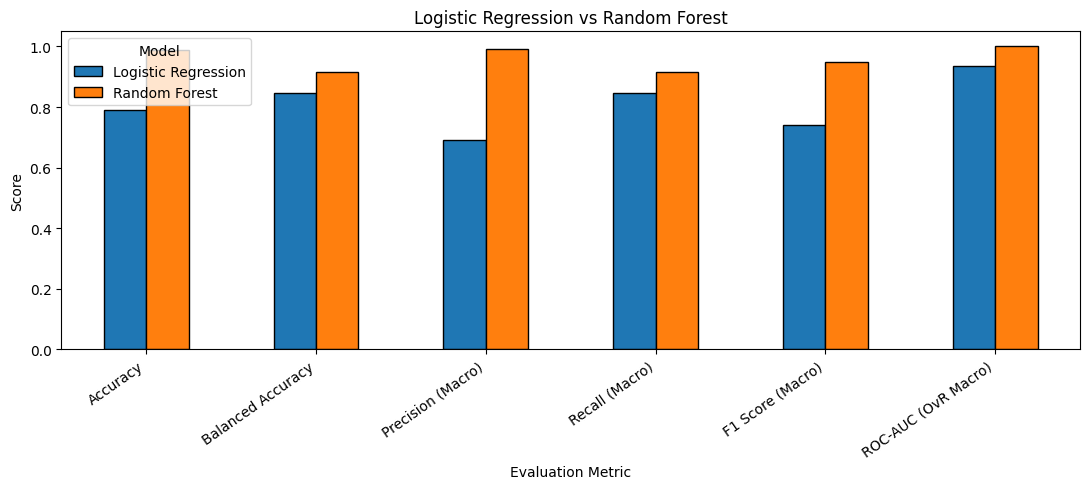

In [15]:
# Bar chart comparison of major metrics
metrics_to_plot = ['Accuracy', 'Balanced Accuracy', 'Precision (Macro)',
                   'Recall (Macro)', 'F1 Score (Macro)', 'ROC-AUC (OvR Macro)']

ax = results[metrics_to_plot].T.plot(kind='bar', figsize=(11, 5), edgecolor='black')
ax.set_title('Logistic Regression vs Random Forest')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.set_xlabel('Evaluation Metric')
plt.xticks(rotation=35, ha='right')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

## Multiclass ROC Curves
The following plots use the One-vs-Rest approach. Each class is treated as the positive class in turn, which helps compare how well the models rank applicants for each risk category.

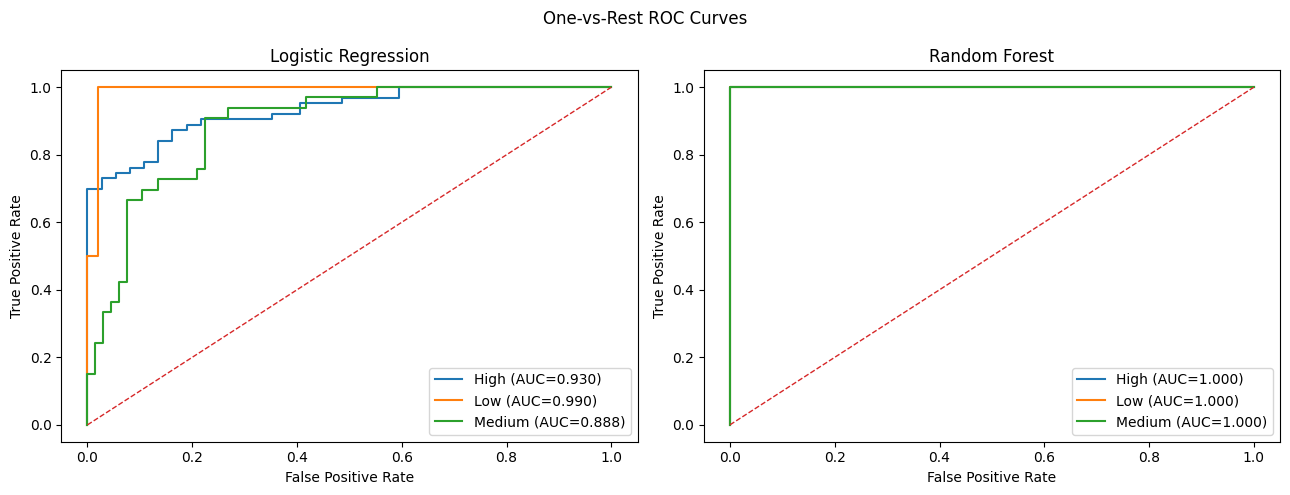

In [16]:
# Multiclass ROC curves
classes = log_model.classes_
y_test_bin = label_binarize(y_test, classes=classes)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name, prob, model_classes in [
    (axes[0], 'Logistic Regression', log_prob, log_model.classes_),
    (axes[1], 'Random Forest', rf_prob, rf_model.classes_)
]:
    for i, cls in enumerate(model_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], prob[:, i])
        ax.plot(fpr, tpr, label=f'{cls} (AUC={auc(fpr, tpr):.3f})')
    ax.plot([0, 1], [0, 1], '--', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend()

plt.suptitle('One-vs-Rest ROC Curves')
plt.tight_layout()
plt.show()

## Feature Analysis
Random Forest provides feature importance values. Logistic Regression coefficients are also shown as absolute mean coefficient magnitudes across the three classes after standardization. These values should be interpreted as model-specific indicators rather than direct causal effects.

,Random Forest Importance
Credit_Score,0.4076
Debt_to_Income_Ratio,0.2332
Late_Payments_Last_2Yrs,0.2202
Age,0.0313
Annual_Income,0.0277
Loan_Amount,0.0274
Employment_Years,0.0273
Loan_Term_Months,0.0133
Existing_Loans_Count,0.0120


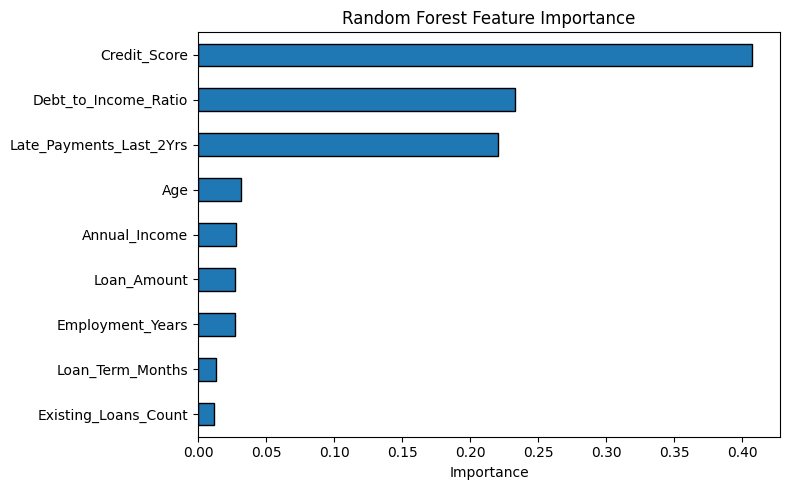

In [17]:
# Random Forest feature importance
rf_importance = pd.Series(
    rf_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

display(rf_importance.to_frame('Random Forest Importance').round(4))

ax = rf_importance.sort_values().plot(kind='barh', figsize=(8, 5), edgecolor='black')
ax.set_title('Random Forest Feature Importance')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

,Mean Absolute Coefficient
Credit_Score,1.8417
Late_Payments_Last_2Yrs,1.4126
Debt_to_Income_Ratio,1.0718
Annual_Income,0.1707
Employment_Years,0.1235
Age,0.0812
Loan_Term_Months,0.0465
Loan_Amount,0.0405
Existing_Loans_Count,0.0038


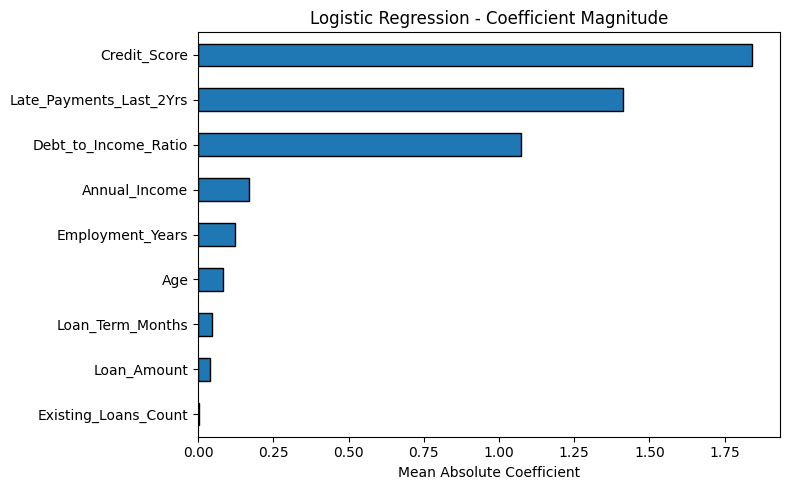

In [18]:
# Logistic Regression coefficient magnitude
log_importance = pd.Series(
    np.mean(np.abs(log_model.coef_), axis=0), index=X.columns
).sort_values(ascending=False)

display(log_importance.to_frame('Mean Absolute Coefficient').round(4))

ax = log_importance.sort_values().plot(kind='barh', figsize=(8, 5), edgecolor='black')
ax.set_title('Logistic Regression - Coefficient Magnitude')
ax.set_xlabel('Mean Absolute Coefficient')
plt.tight_layout()
plt.show()

## Comparative Analysis
The table below automatically identifies the better model for each metric. Because the target is imbalanced, **Macro F1** and **Balanced Accuracy** deserve special attention alongside ordinary accuracy.

In [19]:
# Automatic metric-wise comparison
comparison = results.T.copy()
comparison['Better Model'] = comparison.idxmax(axis=1)
display(comparison.round(4))

best_f1 = results['F1 Score (Macro)'].idxmax()
best_balanced = results['Balanced Accuracy'].idxmax()
best_auc = results['ROC-AUC (OvR Macro)'].idxmax()

print(f'Best Macro F1 Score       : {best_f1}')
print(f'Best Balanced Accuracy    : {best_balanced}')
print(f'Best Multiclass ROC-AUC   : {best_auc}')

Model,Logistic Regression,Random Forest,Better Model
Accuracy,0.7900,0.9900,Random Forest
Balanced Accuracy,0.8456,0.9167,Random Forest
Precision (Macro),0.6925,0.9902,Random Forest
Recall (Macro),0.8456,0.9167,Random Forest
F1 Score (Macro),0.7398,0.9474,Random Forest
ROC-AUC (OvR Macro),0.9358,1.0000,Random Forest


Best Macro F1 Score       : Random Forest
Best Balanced Accuracy    : Random Forest
Best Multiclass ROC-AUC   : Random Forest


In [20]:
# Sample predictions for comparison
prediction_comparison = X_test.copy()
prediction_comparison['Actual_Risk'] = y_test.values
prediction_comparison['Logistic_Prediction'] = log_pred
prediction_comparison['Random_Forest_Prediction'] = rf_pred

display(prediction_comparison.head(15))

,Age,Annual_Income,Employment_Years,Credit_Score,Loan_Amount,Loan_Term_Months,Existing_Loans_Count,Debt_to_Income_Ratio,Late_Payments_Last_2Yrs,Actual_Risk,Logistic_Prediction,Random_Forest_Prediction
156,62,837281,28,469,229785,24,1,0.68,2,High,High,High
151,52,1055588,5,870,307368,48,4,0.12,1,Low,Low,Low
326,57,1443697,21,372,734688,48,1,0.48,2,High,High,High
491,37,1071522,16,651,976578,60,0,0.61,1,High,High,High
185,52,177712,29,664,190507,36,0,0.26,4,Medium,Medium,Medium
18,44,1312928,21,482,151376,24,0,0.15,3,High,High,High
162,40,533934,20,856,855175,60,2,0.13,7,Medium,Medium,Medium
87,45,1212383,9,525,914008,60,4,0.53,8,High,High,High
274,60,921954,28,505,104624,36,0,0.48,0,High,High,High
90,44,842440,25,558,275049,36,2,0.16,5,High,Medium,High


## Result and Conclusion
Both **Logistic Regression** and **Random Forest** were successfully trained to classify applicants into Low, Medium, and High credit-risk categories.

The final comparison should be interpreted from the generated metrics rather than accuracy alone. In particular:

1. **Accuracy** shows overall correctness.
2. **Balanced Accuracy and Macro Recall** show whether all risk groups are being recognized fairly despite class imbalance.
3. **Macro F1-score** balances precision and recall across all three classes.
4. **ROC-AUC** evaluates class-probability ranking performance.
5. **Confusion matrices** reveal which risk categories are most often confused.

The model with stronger Macro F1 and Balanced Accuracy is generally the more suitable choice for this experiment, while the exact choice should also consider the cost of misclassifying a high-risk applicant as lower risk.

### Learning Outcome
This experiment demonstrates how two different classification approaches can be applied to credit-risk assessment and how multiple evaluation metrics provide a more reliable comparison than accuracy alone.